# Анализ самых прослушиваемых треков Spotify в 2024 году

**Датасет:** [Most Streamed Spotify Songs 2024](https://www.kaggle.com/datasets/nelgiriyewithana/most-streamed-spotify-songs-2024) — 4 600 треков и 29 показателей: стримы, лайки, репосты, просмотры, добавления в плейлисты и др. по 11 платформам (Spotify, YouTube, TikTok, Apple Music, Deezer, Pandora, Soundcloud…).

**Заказчик (легенда):** сайт для скачивания музыки. Цель — определить, какие исполнители, треки и альбомы наиболее востребованы у аудитории на различных платформах, чтобы добавить их в базу сайта и использовать в таргетированной рекламе.

**Задачи:**

1. Определить 10 наиболее популярных треков по общим показателям (*All Time Rank*, *Track Score*) без возрастного ограничения.
2. Сформировать удобную таблицу: трек, альбом, исполнитель, дата релиза, ISRC.
3. Построить диаграмму влияния года выпуска трека на его популярность в 2024 году.
4. Построить диаграмму исполнителей с наибольшим числом популярных треков.
5. Вывести статистики *Track Score* по этим исполнителям.
6. Определить, влияет ли наличие возрастного ограничения на популярность на разных платформах.

> Вся логика вынесена в пакет `spotify_analysis` (модули `data`, `analysis`, `plots`), поэтому в ноутбуке — только аналитический нарратив.

## 1. Загрузка и очистка данных

In [1]:
import matplotlib.pyplot as plt

from spotify_analysis import analysis, data, plots

plots.set_plot_style()

raw = data.load_raw_data()
raw.head()

,Track,Album Name,Artist,Release Date,ISRC,All Time Rank,Track Score,Spotify Streams,Spotify Playlist Count,Spotify Playlist Reach,...,SiriusXM Spins,Deezer Playlist Count,Deezer Playlist Reach,Amazon Playlist Count,Pandora Streams,Pandora Track Stations,Soundcloud Streams,Shazam Counts,TIDAL Popularity,Explicit Track
0,MILLION DOLLAR BABY,Million Dollar Baby - Single,Tommy Richman,4/26/2024,QM24S2402528,1,725.4,"390,470,936","30,716","196,631,588",...,684,62.0,"17,598,718",114.0,"18,004,655","22,931","4,818,457","2,669,262",NaN,0
1,Not Like Us,Not Like Us,Kendrick Lamar,5/4/2024,USUG12400910,2,545.9,"323,703,884","28,113","174,597,137",...,3,67.0,"10,422,430",111.0,"7,780,028","28,444","6,623,075","1,118,279",NaN,1
2,i like the way you kiss me,I like the way you kiss me,Artemas,3/19/2024,QZJ842400387,3,538.4,"601,309,283","54,331","211,607,669",...,536,136.0,"36,321,847",172.0,"5,022,621","5,639","7,208,651","5,285,340",NaN,0
3,Flowers,Flowers - Single,Miley Cyrus,1/12/2023,USSM12209777,4,444.9,"2,031,280,633","269,802","136,569,078",...,"2,182",264.0,"24,684,248",210.0,"190,260,277","203,384",NaN,"11,822,942",NaN,0
4,Houdini,Houdini,Eminem,5/31/2024,USUG12403398,5,423.3,"107,034,922","7,223","151,469,874",...,1,82.0,"17,660,624",105.0,"4,493,884","7,006","207,179","457,017",NaN,1


In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Track                       4600 non-null   str    
 1   Album Name                  4600 non-null   str    
 2   Artist                      4595 non-null   str    
 3   Release Date                4600 non-null   str    
 4   ISRC                        4600 non-null   str    
 5   All Time Rank               4600 non-null   str    
 6   Track Score                 4600 non-null   float64
 7   Spotify Streams             4487 non-null   str    
 8   Spotify Playlist Count      4530 non-null   str    
 9   Spotify Playlist Reach      4528 non-null   str    
 10  Spotify Popularity          3796 non-null   float64
 11  YouTube Views               4292 non-null   str    
 12  YouTube Likes               4285 non-null   str    
 13  TikTok Posts                3427 non-null   

В сырых данных несколько проблем:

* пропущенные значения: у показателя `TIDAL Popularity` не заполнено **ни одного** из 4 600 значений; в метриках платформ пропусков от 70 до 3 333 (у Soundcloud отсутствуют данные для ~72 % треков);
* `Release Date`, названия треков, альбомов и исполнителей имеют строковый тип;
* числовые показатели хранятся строками с разделителями тысяч (`"390,470,936"`);
* часть названий повреждена на стороне исходного файла Kaggle (битая кодировка — например, имя трека «Laxed (Siren Beat)» и альбом «Baby Shark»).

Всё это исправляет функция `clean_data`:
пустая колонка удаляется, даты приводятся к `datetime`, текст — к `string`,
метрики — к `int64` (числа очищаются от запятых), а пропуски в метриках
заполняются нулями: отсутствие значения означает отсутствие трека на платформе,
и отдельных статистик по пропускам не требуется.

In [3]:
df = data.clean_data(raw)
df.head()

,Track,Album Name,Artist,Release Date,ISRC,All Time Rank,Track Score,Spotify Streams,Spotify Playlist Count,Spotify Playlist Reach,...,AirPlay Spins,SiriusXM Spins,Deezer Playlist Count,Deezer Playlist Reach,Amazon Playlist Count,Pandora Streams,Pandora Track Stations,Soundcloud Streams,Shazam Counts,Explicit Track
0,MILLION DOLLAR BABY,Million Dollar Baby - Single,Tommy Richman,2024-04-26,QM24S2402528,1,725.4,390470936,30716,196631588,...,40975,684,62,17598718,114,18004655,22931,4818457,2669262,0
1,Not Like Us,Not Like Us,Kendrick Lamar,2024-05-04,USUG12400910,2,545.9,323703884,28113,174597137,...,40778,3,67,10422430,111,7780028,28444,6623075,1118279,1
2,i like the way you kiss me,I like the way you kiss me,Artemas,2024-03-19,QZJ842400387,3,538.4,601309283,54331,211607669,...,74333,536,136,36321847,172,5022621,5639,7208651,5285340,0
3,Flowers,Flowers - Single,Miley Cyrus,2023-01-12,USSM12209777,4,444.9,2031280633,269802,136569078,...,1474799,2182,264,24684248,210,190260277,203384,0,11822942,0
4,Houdini,Houdini,Eminem,2024-05-31,USUG12403398,5,423.3,107034922,7223,151469874,...,12185,1,82,17660624,105,4493884,7006,207179,457017,1


## 2. Топ-10 треков без возрастного ограничения

Отбираем треки с `Explicit Track == 0` и ранжируем по `All Time Rank` и `Track Score`. В этом датасете оба топа совпадают — `top_clean_tracks` проверяет это и падает с ошибкой, если ранжирования разойдутся.

In [4]:
top = analysis.top_clean_tracks(df)
top

,Track,Album Name,Artist,Release Date,ISRC
1,MILLION DOLLAR BABY,Million Dollar Baby - Single,Tommy Richman,2024-04-26,QM24S2402528
2,i like the way you kiss me,I like the way you kiss me,Artemas,2024-03-19,QZJ842400387
3,Flowers,Flowers - Single,Miley Cyrus,2023-01-12,USSM12209777
4,Beautiful Things,Beautiful Things,Benson Boone,2024-01-18,USWB12307016
5,LUNCH,HIT ME HARD AND SOFT,Billie Eilish,2024-05-17,USUM72401991
6,bathroom floor,bathroom floor,Kids With Buns,2022-10-07,NLC242100307
7,Fortnight (feat. Post Malone),THE TORTURED POETS DEPARTMENT,Taylor Swift,2024-04-18,USUG12401028
8,BLUE,HIT ME HARD AND SOFT,Billie Eilish,2024-05-17,USUM72401996
9,As It Was,As It Was,Harry Styles,2022-03-31,USSM12200612
10,Future,Future,official sound studio,2024-01-10,RUA1H2415548


Наиболее популярные треки без возрастного ограничения (одинаково по *All Time Rank* и *Track Score*): **«MILLION DOLLAR BABY»** Tommy Richman, **«i like the way you kiss me»** Artemas, **«Flowers»** Miley Cyrus, **«Beautiful Things»** Benson Boone, **«LUNCH»** Billie Eilish, **«bathroom floor»** Kids With Buns, **«Fortnight (feat. Post Malone)»** Taylor Swift, **«BLUE»** Billie Eilish, **«As It Was»** Harry Styles и **«Future»** official sound studio.

## 3. Статистики Track Score по топ-10 исполнителям

In [5]:
stats = analysis.artist_track_score_stats(df)
stats

Artist,Taylor Swift,Drake,Bad Bunny,KAROL G,The Weeknd,Travis Scott,Billie Eilish,Ariana Grande,Future,Post Malone
count,63.00,63.00,60.00,32.00,31.00,30.00,27.00,26.00,23.00,22.00
mean,40.90,45.58,47.30,52.34,48.69,47.33,82.26,51.28,62.96,72.22
std,40.36,28.02,36.58,38.67,36.83,32.51,81.52,48.93,65.27,66.18
min,19.70,20.10,19.60,19.60,20.50,19.90,19.60,19.50,19.70,21.60
median,28.20,33.20,32.20,33.95,38.00,38.35,54.70,33.30,33.80,52.40
max,297.60,122.70,184.80,167.80,194.00,139.50,316.30,262.80,308.20,322.10


Самый «продуктивный» исполнитель 2024 года по качеству — **Billie Eilish**: у неё наиболее высокие среднее (82.3) и медианное (54.7) значения *Track Score*. Высокое стандартное отклонение (81.5) говорит о большом разбросе: в каталоге есть как треки с очень высоким рейтингом, так и с очень низким.

У **Drake** — самое низкое стандартное отклонение (28.0): рейтинги его треков стабильно умеренные, при этом пиковые значения заметно ниже, чем у остальных исполнителей топ-10 (максимум 122.7 против 316.3 у Billie Eilish).

## 4. Лидеры платформ

Таблица `platform_leaders` определяет самый популярный трек по каждому показателю каждой платформы. Для Soundcloud (единственной платформы, где доминируют explicit-треки) лидер выбирается среди треков без возрастного ограничения — по требованию заказчика.

In [6]:
leaders = analysis.platform_leaders(df)
leaders

,Track,Album Name,Artist,Release Date,ISRC
Metric,,,,,
Spotify Streams,Blinding Lights,Blinding Lights,The Weeknd,2019-11-29,USUG11904206
Spotify Playlist Count,Blinding Lights,Blinding Lights,The Weeknd,2019-11-29,USUG11904206
Spotify Playlist Reach,Espresso,Espresso,Sabrina Carpenter,2024-04-12,USUM72403305
Spotify Popularity,A Bar Song (Tipsy),A Bar Song (Tipsy),Shaboozey,2024-04-12,USUYG1541249
YouTube Views,Baby Shark,-,Pinkfong,2015-12-01,KRE671700001
YouTube Likes,Dynamite,Dynamite,BTS,2020-08-21,QM7282022872
YouTube Playlist Reach,As It Was,As It Was,Harry Styles,2022-03-31,USSM12200612
TikTok Posts,Laxed (Siren Beat),Laxed (Siren Beat),Jawsh 685,2020-04-24,NZAM02001128
TikTok Likes,Monkeys Spinning Monkeys,SteamFun - Single,Kevin MacLeod,2011-05-16,USUAN1400011


Любопытные наблюдения. Лидер YouTube — детская песня **«Baby Shark»** с 16,3 млрд просмотров: с ней связан криминальный инцидент — сотрудников тюрьмы округа Оклахома (США) обвинили в жестоком обращении с заключёнными за то, что они включали им эту песню в качестве наказания. По *Spotify Streams* вне конкуренции **«Blinding Lights»** The Weeknd (4,28 млрд). А самым часто постящимся звуком в TikTok остаётся **«Laxed (Siren Beat)»** Jawsh 685 (42,9 млн постов) — в исходном файле его название повреждено кодировкой, поэтому таблица использует значение из конфигурации проекта (ISRC трека при этом корректен).

## 5. Диаграммы

### 5.1. Количество популярных треков по году выпуска

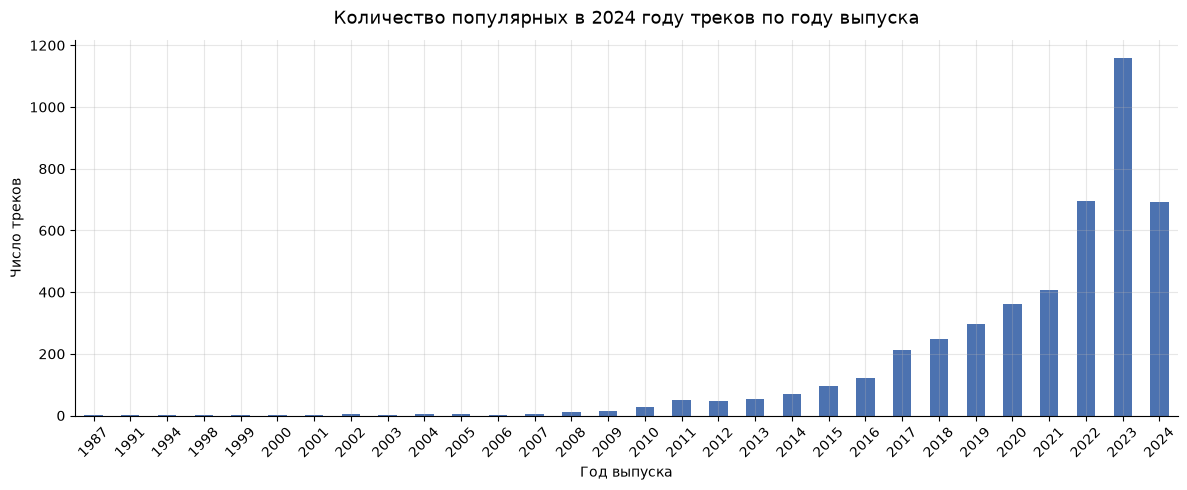

In [7]:
yearly = analysis.tracks_by_release_year(df)
fig, ax = plots.plot_tracks_by_release_year(yearly)
plt.show()

Наибольшее число треков, популярных в 2024 году, выпущено за последние три года. Рост количества «вечно зелёных» треков с годом выпуска близок к экспоненциальному, кроме последнего года: данных за 2024-й на момент публикации датасета ещё мало.

### 5.2. Топ-10 исполнителей по количеству популярных треков

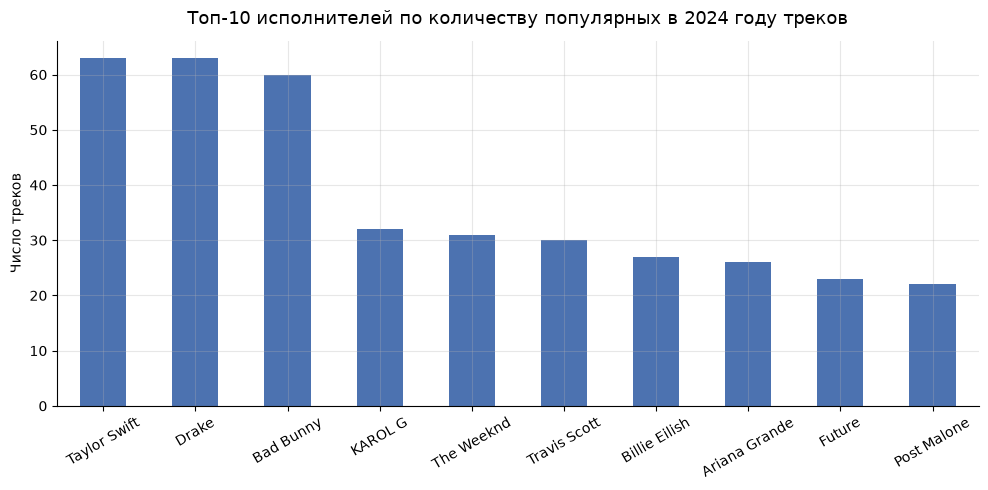

In [8]:
top_artists = analysis.top_artists_by_track_count(df)
fig, ax = plots.plot_top_artists(top_artists)
plt.show()

Больше всего треков в рейтингах 2024 года выпустили **Taylor Swift** и **Drake** (по 63), **Bad Bunny** (60), далее — KAROL G, The Weeknd, Travis Scott, Billie Eilish, Ariana Grande, Future. Десятую строку делят **Post Malone** и **Peso Pluma** — у обоих по 22 трека; пандасовский `value_counts` отдаёт её Post Malone.

### 5.3. Суммарные показатели платформ: треки с возрастным ограничением и без него

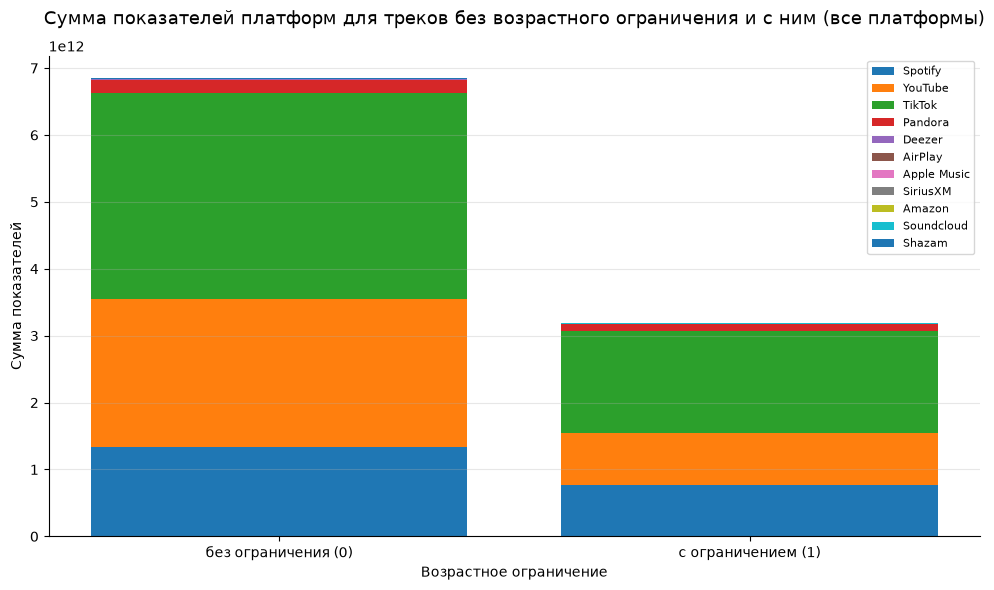

In [9]:
totals = analysis.platform_totals_by_explicit(df)

fig, ax = plots.plot_platform_totals_by_explicit(totals, title_suffix="(все платформы)")
plt.show()

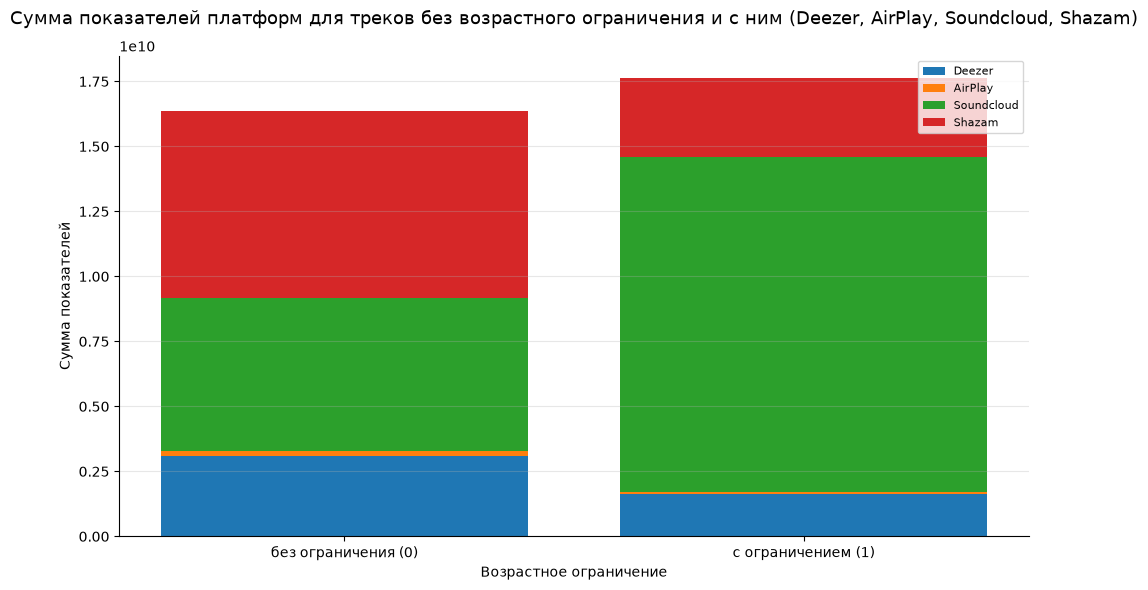

In [10]:
fig, ax = plots.plot_platform_totals_by_explicit(
    totals, platforms=["Deezer", "AirPlay", "Soundcloud", "Shazam"],
    title_suffix="(Deezer, AirPlay, Soundcloud, Shazam)",
)
plt.show()

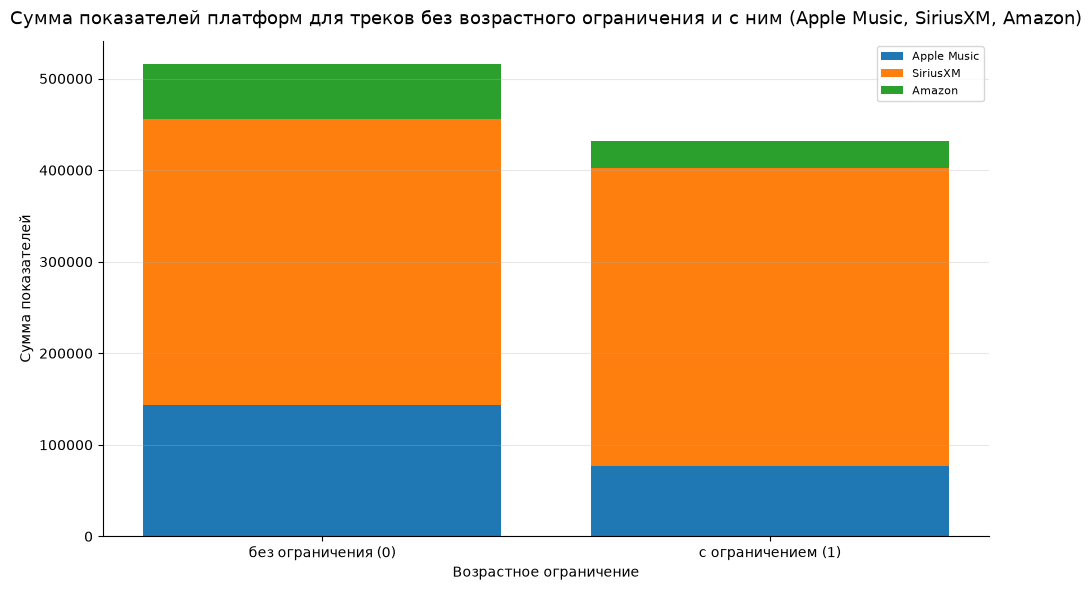

In [11]:
fig, ax = plots.plot_platform_totals_by_explicit(
    totals, platforms=["Apple Music", "SiriusXM", "Amazon"],
    title_suffix="(Apple Music, SiriusXM, Amazon)",
)
plt.show()

На большинстве платформ суммарные показатели треков **без** возрастного ограничения выше. Исключения — SiriusXM и особенно Soundcloud, где доминируют explicit-треки.

## Итоговые выводы

1. **Топ-10 треков** без возрастного ограничения совпадает по *All Time Rank* и *Track Score*; лидируют «MILLION DOLLAR BABY» Tommy Richman и «i like the way you kiss me» Artemas.
2. **Свежесть имеет значение**: популярность трека в 2024 году экспоненциально падает с возрастом релиза; больше половины хитов выпущено в 2022–2024 годах.
3. **Лидеры по числу хитов** — Taylor Swift и Drake (по 63 трека), Bad Bunny (60).
4. **Качество против стабильности**: у Billie Eilish — самые высокие средний и медианный *Track Score* при большом разбросе; у Drake — самый стабильный, но умеренный рейтинг.
5. **Возрастное ограничение в основном снижает охват**: на большинстве платформ clean-версии суммарно популярнее; исключения — SiriusXM и Soundcloud.
6. **Таблица лидеров платформ** определяет самый популярный трек по каждому из 20 показателей: от «Blinding Lights» (Spotify Streams) до «Baby Shark» (YouTube Views).

## Как воспроизвести

Ноутбук — только нарратив; полный пайплайн запускается одной командой и пересобирает таблицы (`reports/tables/`) и диаграммы (`reports/figures/`):

```bash
make run          # или: spotify-analysis  /  python -m spotify_analysis
make test         # тесты (pytest)
```